Number of hours with AQI exactly 500: 3820


C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:23: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df['AQI'].resample('M').mean()
C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df.index.month, y=df['AQI'], ax=axes[2], palette="Blues")
C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df.index.hour, y=df['AQI'], ax=axes[3], palette="Oranges")


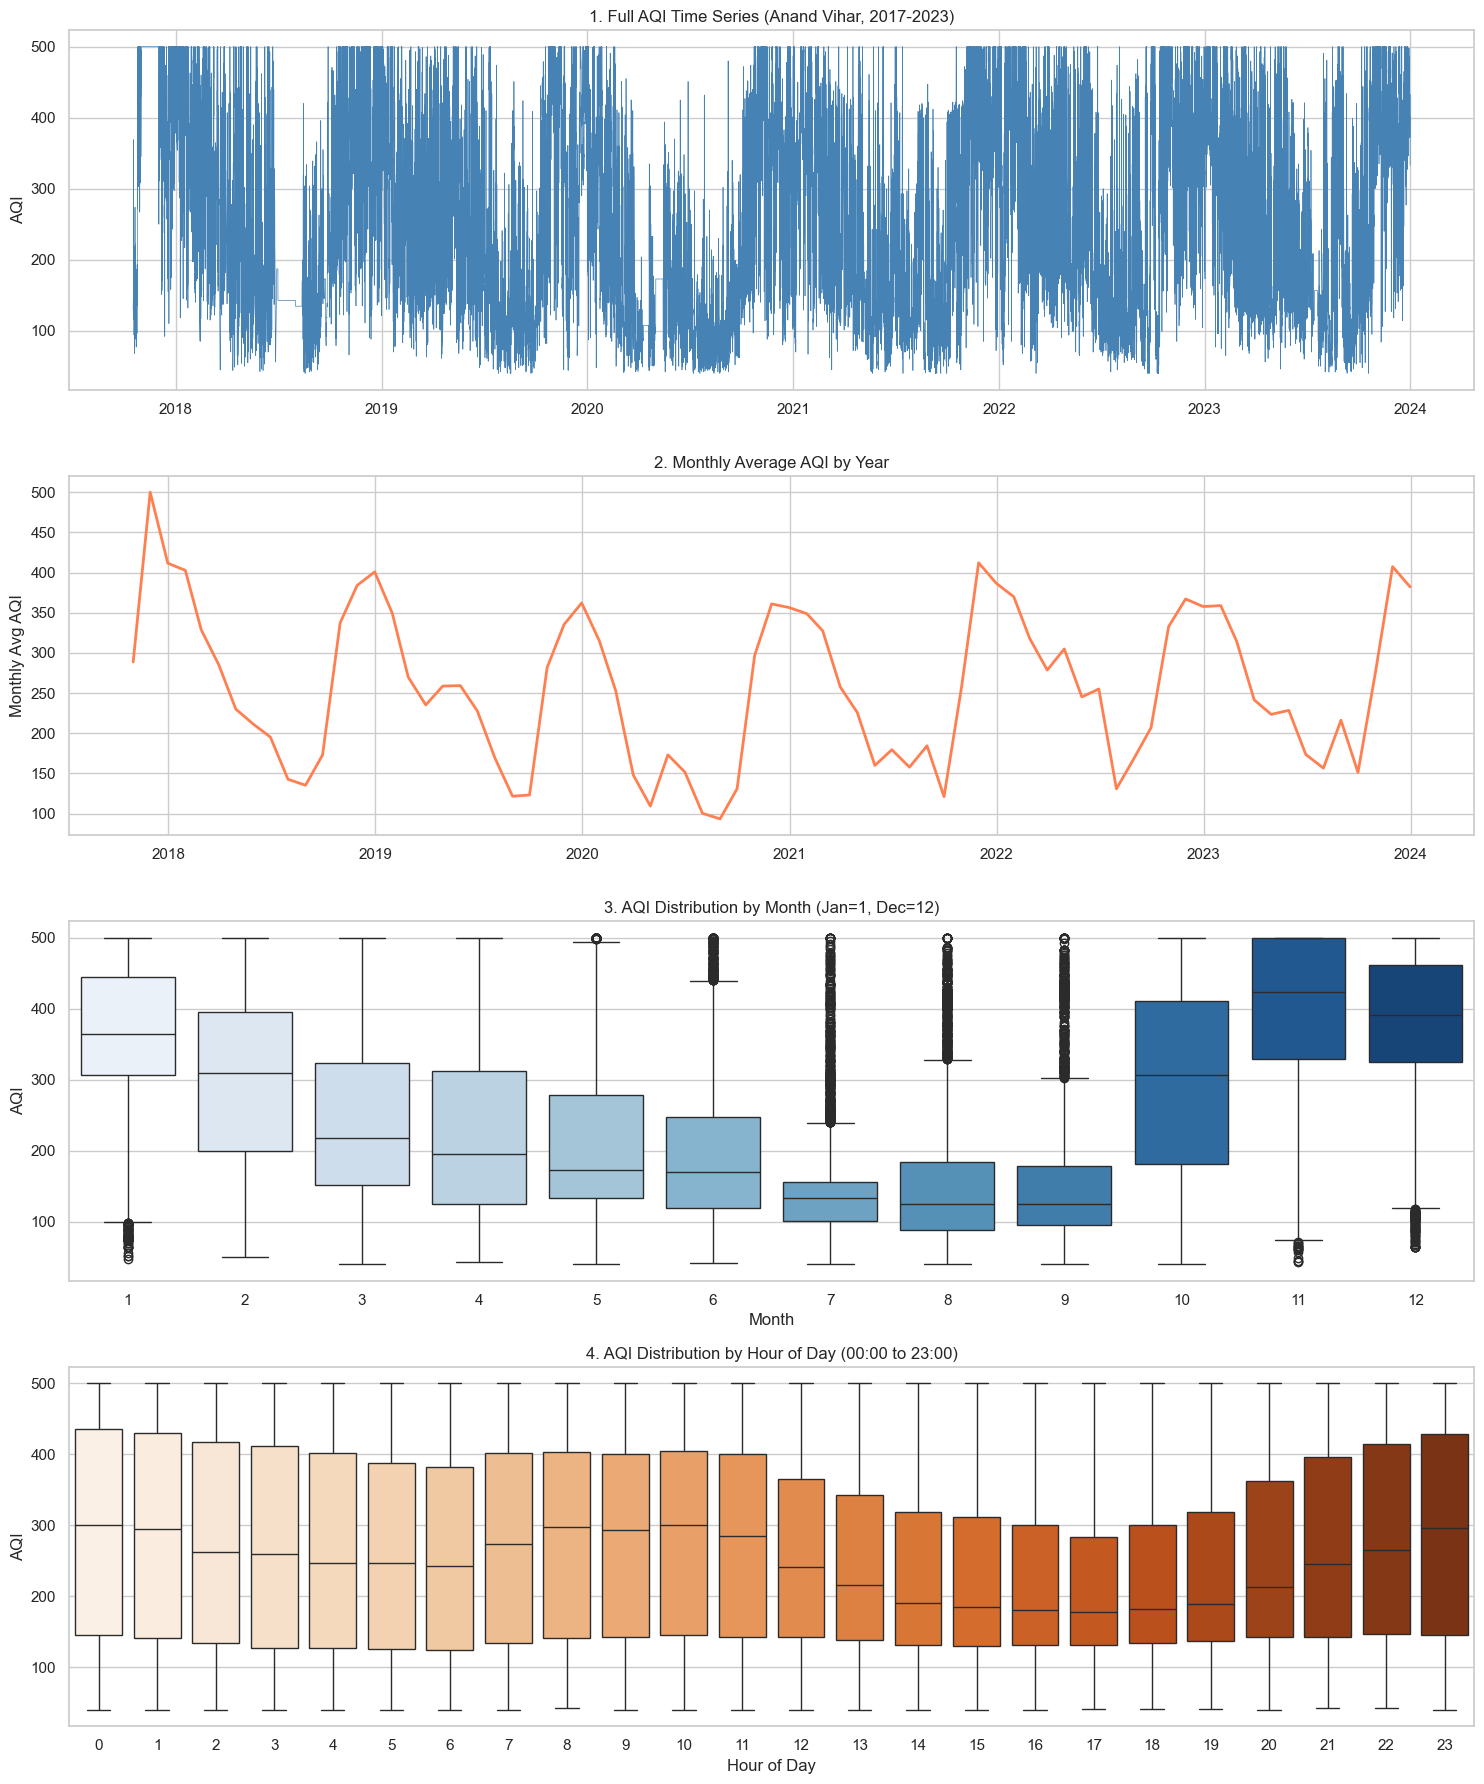

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the clean Stage 0 data
df = pd.read_csv("../Dataset/final_clean_aqi_v3.csv", parse_dates=['Datetime'])
df.set_index('Datetime', inplace=True)

# Quick check: How many hours are stuck at exactly 500? (The scale cap)
cap_count = (df['AQI'] == 500).sum()
print(f"Number of hours with AQI exactly 500: {cap_count}")

# Set a nice visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 1, figsize=(15, 18))

# 1. Full Time Series Plot
axes[0].plot(df.index, df['AQI'], linewidth=0.5, color='steelblue')
axes[0].set_title('1. Full AQI Time Series (Anand Vihar, 2017-2023)')
axes[0].set_ylabel('AQI')

# 2. Monthly Average by Year
monthly_avg = df['AQI'].resample('M').mean()
axes[1].plot(monthly_avg.index, monthly_avg, color='coral', linewidth=2)
axes[1].set_title('2. Monthly Average AQI by Year')
axes[1].set_ylabel('Monthly Avg AQI')

# 3. Average by Month (To see the seasonal U-shape)
sns.boxplot(x=df.index.month, y=df['AQI'], ax=axes[2], palette="Blues")
axes[2].set_title('3. AQI Distribution by Month (Jan=1, Dec=12)')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('AQI')

# 4. Average by Hour of Day
sns.boxplot(x=df.index.hour, y=df['AQI'], ax=axes[3], palette="Oranges")
axes[3].set_title('4. AQI Distribution by Hour of Day (00:00 to 23:00)')
axes[3].set_xlabel('Hour of Day')
axes[3].set_ylabel('AQI')

plt.tight_layout()
plt.show()